=== LINEAR REGRESSION ===
MSE: 17.6037
R2 Score: 0.1415
-----------------------------------
=== LOGISTIC REGRESSION ===
Accuracy:  0.7342
Precision: 0.7541
Recall:    0.8846
F1-Score:  0.8142

=== DECISION TREE ===
Accuracy:  0.7342
Precision: 0.7246
Recall:    0.9615
F1-Score:  0.8264



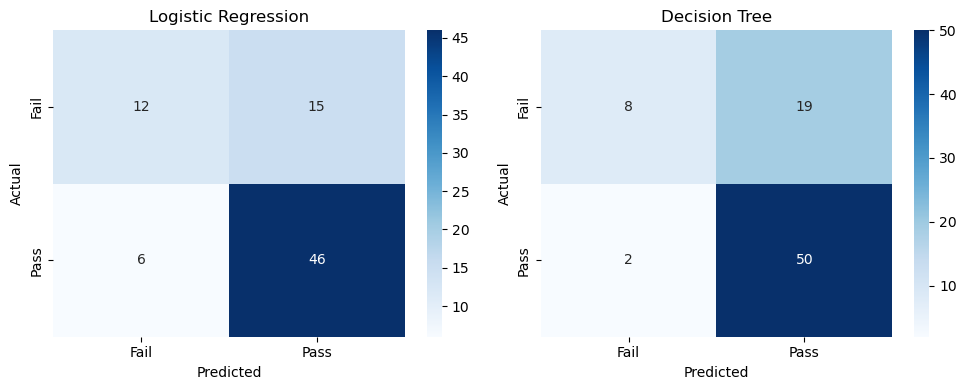

In [2]:

# Roll No: 24-ai-087

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, mean_squared_error, r2_score

 Dataset
df = pd.read_csv('student-mat.csv', sep=';')

Target Column
df['passed'] = np.where(df['G3'] >= 10, 1, 0)

 #Categorical
df = pd.get_dummies(df, drop_first=True)

 Features and Targets 
X = df.drop(columns=['G1', 'G2', 'G3', 'passed'])
y_reg = df['G3']       # For Linear Regression
y_cls = df['passed']   # For Classification

 Split Dataset
X_train, X_test, y_train_reg, y_test_reg, y_train_cls, y_test_cls = train_test_split(
    X, y_reg, y_cls, test_size=0.2, random_state=42
)

# Linear Regression 
reg = LinearRegression()
reg.fit(X_train, y_train_reg)
y_pred_reg = reg.predict(X_test)

print("=== LINEAR REGRESSION ===")
print("MSE:", round(mean_squared_error(y_test_reg, y_pred_reg), 4))
print("R2 Score:", round(r2_score(y_test_reg, y_pred_reg), 4))
print("-" * 35)

# Classification 
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42)
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train_cls)
    y_pred = model.predict(X_test)
    
    print(f"=== {name.upper()} ===")
    print(f"Accuracy:  {accuracy_score(y_test_cls, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test_cls, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_test_cls, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_test_cls, y_pred):.4f}\n")
    
    # Confusion Matrix
    cm = confusion_matrix(y_test_cls, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()